# Exoplaneten — de oorspronkelijke SOM met nieuwe NASA-data

Een opnieuw uitvoerbare proef voor Leo. **We kiezen vooraf twaalf SOM-plekken; twaalf bezette plekken bewijzen niet dat er twaalf natuurlijke planeetsoorten zijn.**

## Kort resultaat
De samenvatting hieronder wordt uit de uitgevoerde berekening opgebouwd. De bewaarde NASA-momentopname maakt deze proef herhaalbaar.

## Context en methode
De online update uit `SelfOrganisedMap.py` is overgezet naar NumPy/Numba. De regel, een rij van 12 knopen, 1.600 volledige doorgangen, beginleersnelheid 0,05 en buurstraal 4 blijven behouden. Numba versnelt de lussen; er wordt geen ander clustermodel gebruikt. De gewichten worden na de laatste update uitgelezen; de oude code bewaarde daarvoor nog de voorlaatste toestand.

### Belangrijke aannames
- Tien van de dertien oude eigenschappen zijn beschikbaar: massa, straal, dichtheid, instraling, evenwichtstemperatuur, omlooptijd, stermassa, sterstraal, stertemperatuur en sterlichtkracht. Oppervlaktedruk, planeethelderheid op maan-afstand en schijnbare stergrootte worden weggelaten. Dit is **geen exacte vergelijking met het oude resultaat**.
- Net als vroeger: lineaire min-maxschaling per eigenschap; geen logtransformatie of invulling door ons. De spreidingsgrafiek gebruikt logassen voor de leesbaarheid, niet voor de training.
- NASA geeft sterlichtkracht als log10(L/Lzon); die wordt eerst naar L/Lzon omgezet. Dichtheid is nu in g/cm³; een vaste eenhedenfactor verandert min-maxschaling niet.
- PSCompPars combineert bronnen en bevat door NASA berekende waarden. Ook literatuurwaarden kunnen modelafhankelijk zijn. 'Niet ingevuld' betekent dus niet 'zonder aannames gemeten'.
- Geen betwiste bevestigingen, limietwaarden, niet-positieve waarden of onvolledige rijen. Hoofdproef bevat minimum-massa’s (M sin i), die niet gelijk zijn aan ware massa’s.
- De hoofdproef gebruikt vaste alfabetische rijvolgorde. Startgewichten worden met drie seeds gecontroleerd. Een extra controle gebruikt een eenmalig geschudde rijvolgorde, vervolgens vast per epoch. De oude CSV was ongeveer op omlooptijd gesorteerd.
- De controleproef sluit ingevulde massa/straal en minimum-massa’s uit, maar selecteert daardoor een andere, sterk door transits gedomineerde populatie. De controles isoleren dus niet één afzonderlijk causaal effect.

Dezelfde schaalmethode en tien eigenschappen bevatten onderlinge afhankelijkheden. Dichtheid, massa en straal hangen samen; instraling en evenwichtstemperatuur ook. Groepsgrenzen zijn voorlopig.

## Instellen
Pak de hele projectmap uit en open dit notebook in `modern_som`. Eenmalig zo nodig:

```python
%pip install -r requirements.txt
```

De bewaarde momentopname wordt standaard gebruikt. Voor een nieuwe download: voer `python download_data.py` uit; dit overschrijft de lokale momentopname en bronmetadata. Voer daarna dit notebook opnieuw uit. Bewaar oude resultaten eerst apart als je datums wilt vergelijken.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
import analysis
from analysis import prepare, fit, online_som, FEATURES, LABELS, ROOT
raw, complete, strict, audit, provenance = prepare()
display(Markdown(f"**Opgehaald (UTC):** {provenance['retrieved_utc']}  \n**NASA-tabel:** PSCompPars; één rij per planeet.  \n**SHA-256:** `{provenance['sha256']}`"))

**Opgehaald (UTC):** 2026-10-17T23:36:52.955890+00:00  
**NASA-tabel:** PSCompPars; één rij per planeet.  
**SHA-256:** `dd989b041458fe5312fbd37b414706b77b45f685922f4f9ed16b8b55fe173933`

## Data
De download omvat de bevestigde planeten uit de gekozen NASA-tabel, inclusief de statusvlag; de analysefilter wordt hieronder zichtbaar gemaakt. De kolom `berekend_door_NASA` telt alle als berekend gemarkeerde waarden vóór selectie. Ontbrekend/limiet is eveneens vóór selectie.

In [2]:
display(pd.DataFrame({'Selectie':['NASA-rijen','Hoofdproef','Uitgesloten uit hoofdproef','Strenge controle'],'Aantal':[len(raw),len(complete),len(raw)-len(complete),len(strict)]}))
display(audit)

,Selectie,Aantal
0,NASA-rijen,6451
1,Hoofdproef,5481
2,Uitgesloten uit hoofdproef,970
3,Strenge controle,1546


,eigenschap,NASA_kolom,ontbrekend_of_limiet,berekend_door_NASA
0,Massa (aarde),pl_bmasse,269,3035
1,Straal (aarde),pl_rade,55,1539
2,Dichtheid (g/cm³),pl_dens,221,4740
3,Instraling (aarde),pl_insol,642,1325
4,Evenwichtstemp. (K),pl_eqt,543,1090
5,Omlooptijd (dagen),pl_orbper,360,0
6,Stermassa (zon),st_mass,9,0
7,Sterstraal (zon),st_rad,332,0
8,Stertemperatuur (K),st_teff,308,0
9,Sterlichtkracht (zon),st_lum,326,162


## Controle van de rekenregel
Op een klein voorbeeld vergelijken we de versnelde update numeriek met de rechtstreeks uitgeschreven NumPy-update uit het oude programma. Dit controleert de overzetting, niet de wetenschappelijke betekenis van de groepen.

In [3]:
rng=np.random.default_rng(7)
test_x=rng.uniform(size=(8,3)); initial=rng.uniform(size=(12,3))
reference=initial.copy()
for epoch in range(5):
    decay=1-epoch/5
    for vector in test_x:
        winner=np.argmin(np.linalg.norm(reference-vector,axis=1))
        influence=.05*decay*np.exp(-(np.arange(12)-winner)**2/(4*decay)**2)
        reference += influence[:,None]*(vector-reference)
accelerated=online_som(test_x,initial.copy(),epochs=5)
np.testing.assert_allclose(accelerated,reference,atol=1e-12,rtol=1e-12)
print('Update komt overeen met de oorspronkelijke formule.')

Update komt overeen met de oorspronkelijke formule.


## Trainen
De hoofdproef, twee herhalingen met andere startgewichten, de volgordecontrole en de strenge gegevenscontrole worden uitgevoerd. Alle resultaten worden in `results` opgeslagen. Groepsnummers zijn plekken op de kaart en kunnen tussen trainingen wisselen.

In [4]:
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    summary=analysis.run()

In [5]:
main=summary['main']; control=summary['strict_control']; order=summary['fixed_shuffled_order_control']
aris=[r['adjusted_rand_vs_seed42'] for r in summary['repeats']]
display(Markdown(f"""### Uitgevoerde samenvatting
- **{summary['archive_rows']:,}** planeten opgehaald; **{main['n']:,}** gebruikt.
- Alle **{main['occupied_nodes']}** SOM-plekken zijn bezet.
- **{summary['mass_calculated_in_main']:,}** ingevulde massa’s, **{summary['radius_calculated_in_main']:,}** ingevulde stralen en **{summary['minimum_mass_in_main']:,}** minimum-massa’s in de hoofdproef. Deze aantallen mogen niet worden opgeteld: ze kunnen overlappen.
- Andere startgewichten: overeenstemming ARI **{aris}**. ARI 1 betekent dezelfde indeling, los van groepsnummers; rond 0 is kansniveau.
- Een andere vaste rijvolgorde: ARI **{order['adjusted_rand_vs_main']:.3f}**.
- Controle met **{control['n']:,}** planeten: ARI **{control['adjusted_rand_vs_main_shared_planets']:.3f}** op dezelfde planeten. De controle is apart getraind en geschaald; dit is geen zuivere test van alleen geschatte waarden.
- Topografische fout hoofdproef: **{main['topographic_error']:.1%}**. Bij die fractie liggen de twee best passende SOM-plekken niet naast elkaar. Dat beperkt hoe letterlijk we de rij als vloeiende ordening mogen lezen.
"""))

### Uitgevoerde samenvatting
- **6,451** planeten opgehaald; **5,481** gebruikt.
- Alle **12** SOM-plekken zijn bezet.
- **2,825** ingevulde massa’s, **1,094** ingevulde stralen en **819** minimum-massa’s in de hoofdproef. Deze aantallen mogen niet worden opgeteld: ze kunnen overlappen.
- Andere startgewichten: overeenstemming ARI **[1.0, 1.0]**. ARI 1 betekent dezelfde indeling, los van groepsnummers; rond 0 is kansniveau.
- Een andere vaste rijvolgorde: ARI **0.975**.
- Controle met **1,546** planeten: ARI **0.407** op dezelfde planeten. De controle is apart getraind en geschaald; dit is geen zuivere test van alleen geschatte waarden.
- Topografische fout hoofdproef: **27.1%**. Bij die fractie liggen de twee best passende SOM-plekken niet naast elkaar. Dat beperkt hoe letterlijk we de rij als vloeiende ordening mogen lezen.


## Resultaten — bezetting en kenmerken
Boven: aantal planeten per plek. Onder: lage tot hoge kenmerken binnen de gebruikte populatie. De kleuren tonen de mediaan van percentielrangen; de training zelf gebruikte min-maxgeschaalde waarden.

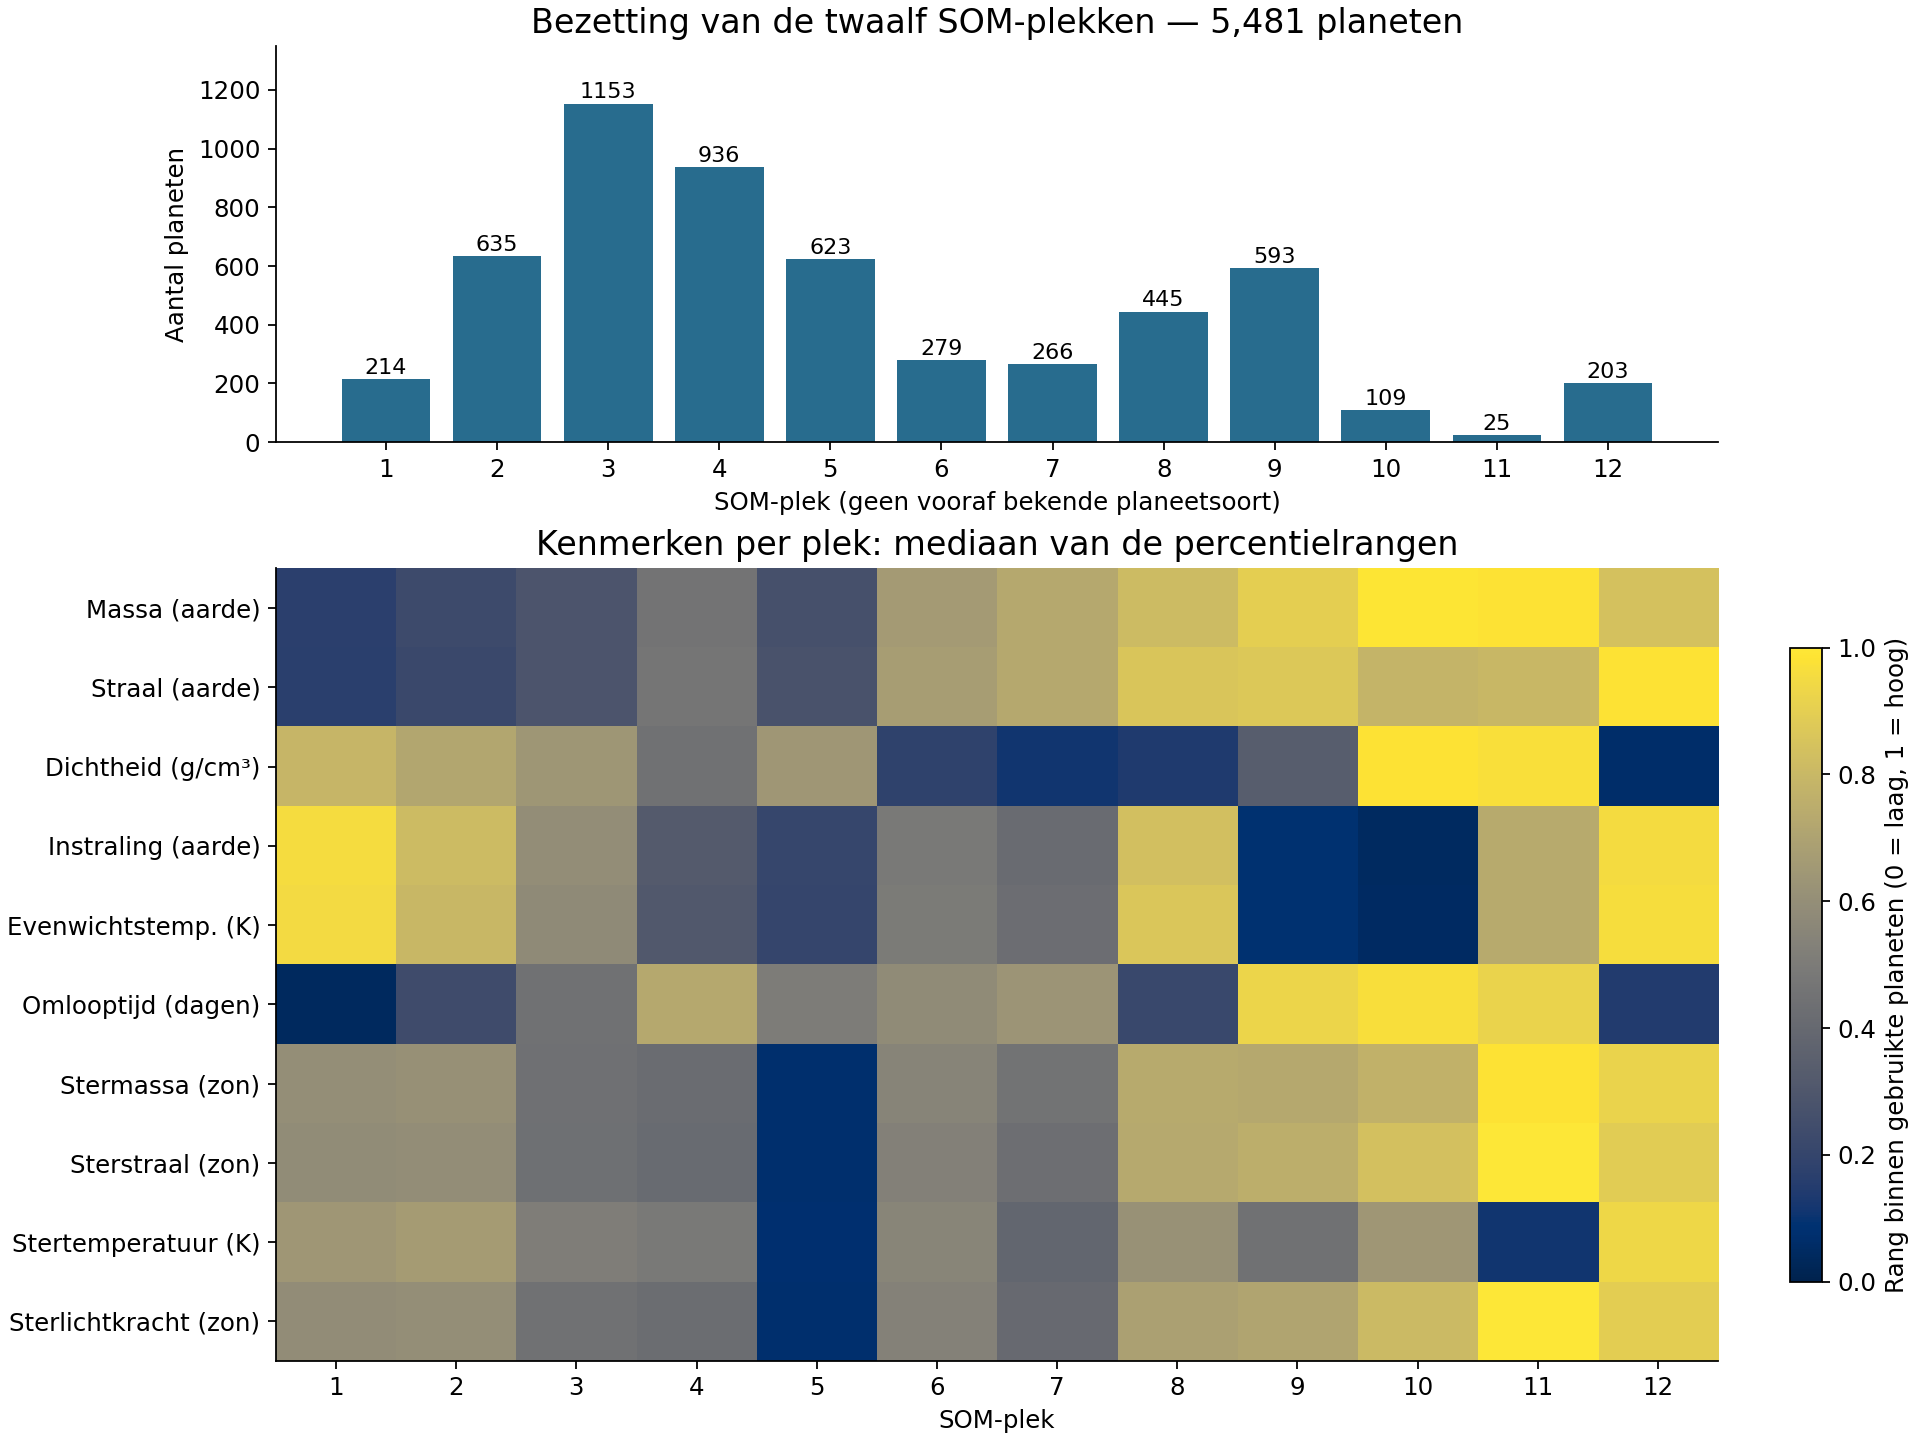

In [6]:
display(Image(filename=str(ROOT/'results/som_overzicht.png')))

### Exacte groepsprofielen
Medians in de oorspronkelijke fysieke eenheden; de sterlichtkracht is lineair. Een mediaan beschrijft de typische waarde per eigenschap, niet één werkelijk bestaande planeet.

In [7]:
profiles=pd.read_csv(ROOT/'results/groepsprofielen.csv')
profiles=profiles.rename(columns=dict(zip(FEATURES,LABELS)))
display(profiles.round(3))

,SOM_groep,aantal,Massa (aarde),Straal (aarde),Dichtheid (g/cm³),Instraling (aarde),Evenwichtstemp. (K),Omlooptijd (dagen),Stermassa (zon),Sterstraal (zon),Stertemperatuur (K),Sterlichtkracht (zon)
0,1,214,3.005,1.510,4.815,1853.655,1734.50,1.429,1.014,1.044,5765.50,1.185
1,2,635,3.750,1.700,4.130,468.542,1200.00,4.140,1.020,1.053,5789.00,1.216
2,3,1153,4.700,1.990,3.350,121.000,852.00,8.735,0.930,0.917,5587.00,0.733
3,4,936,7.610,2.665,2.245,21.840,551.22,32.595,0.914,0.899,5544.00,0.688
4,5,623,4.310,1.930,3.420,7.204,427.00,10.910,0.520,0.500,3740.00,0.046
5,6,279,23.800,5.300,0.882,67.435,761.00,14.709,0.984,0.990,5643.77,0.991
6,7,266,85.757,10.077,0.556,42.081,683.00,18.202,0.938,0.911,5305.00,0.635
7,8,445,282.549,13.110,0.690,556.616,1377.00,3.915,1.090,1.230,5731.00,1.677
8,9,593,740.544,13.300,1.770,0.907,273.57,711.000,1.083,1.264,5466.00,1.827
9,10,109,4958.123,12.200,14.700,0.159,184.72,2500.000,1.120,1.456,5764.23,2.610


### Massa en straal
De hoofdproef bevat ingevulde waarden die op een voorgeschreven massa-straalrelatie kunnen liggen. Een herkenbare lijn daarin is dus niet automatisch een nieuwe ontdekking. De kleuren en groepsnummers worden per training bepaald; dezelfde kleur aan beide kanten betekent niet dezelfde familie.

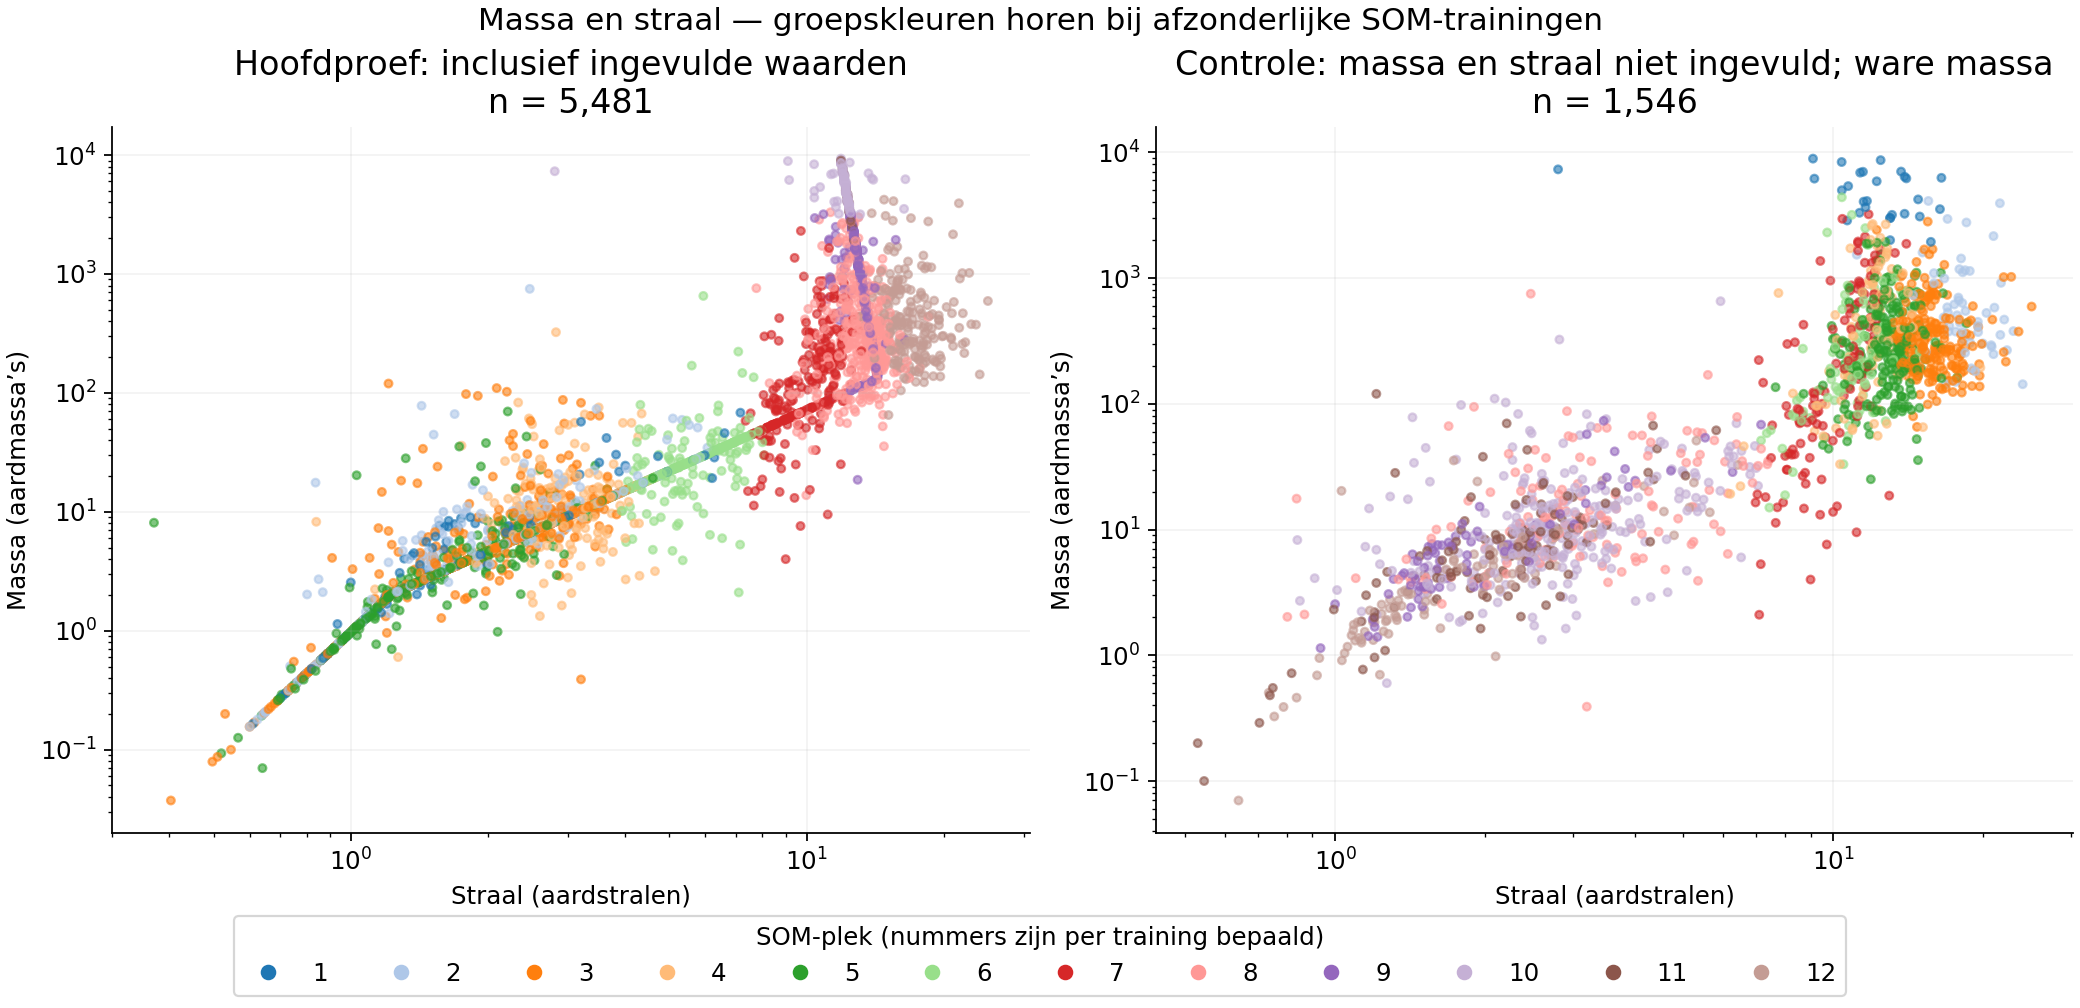

In [8]:
display(Image(filename=str(ROOT/'results/massa_straal.png')))

### Selectie door de meetmethode
De volledigheidseis verandert welke ontdekkingsmethoden vertegenwoordigd zijn. De strenge controle is daardoor geen representatieve dwarsdoorsnede van alle exoplaneten.

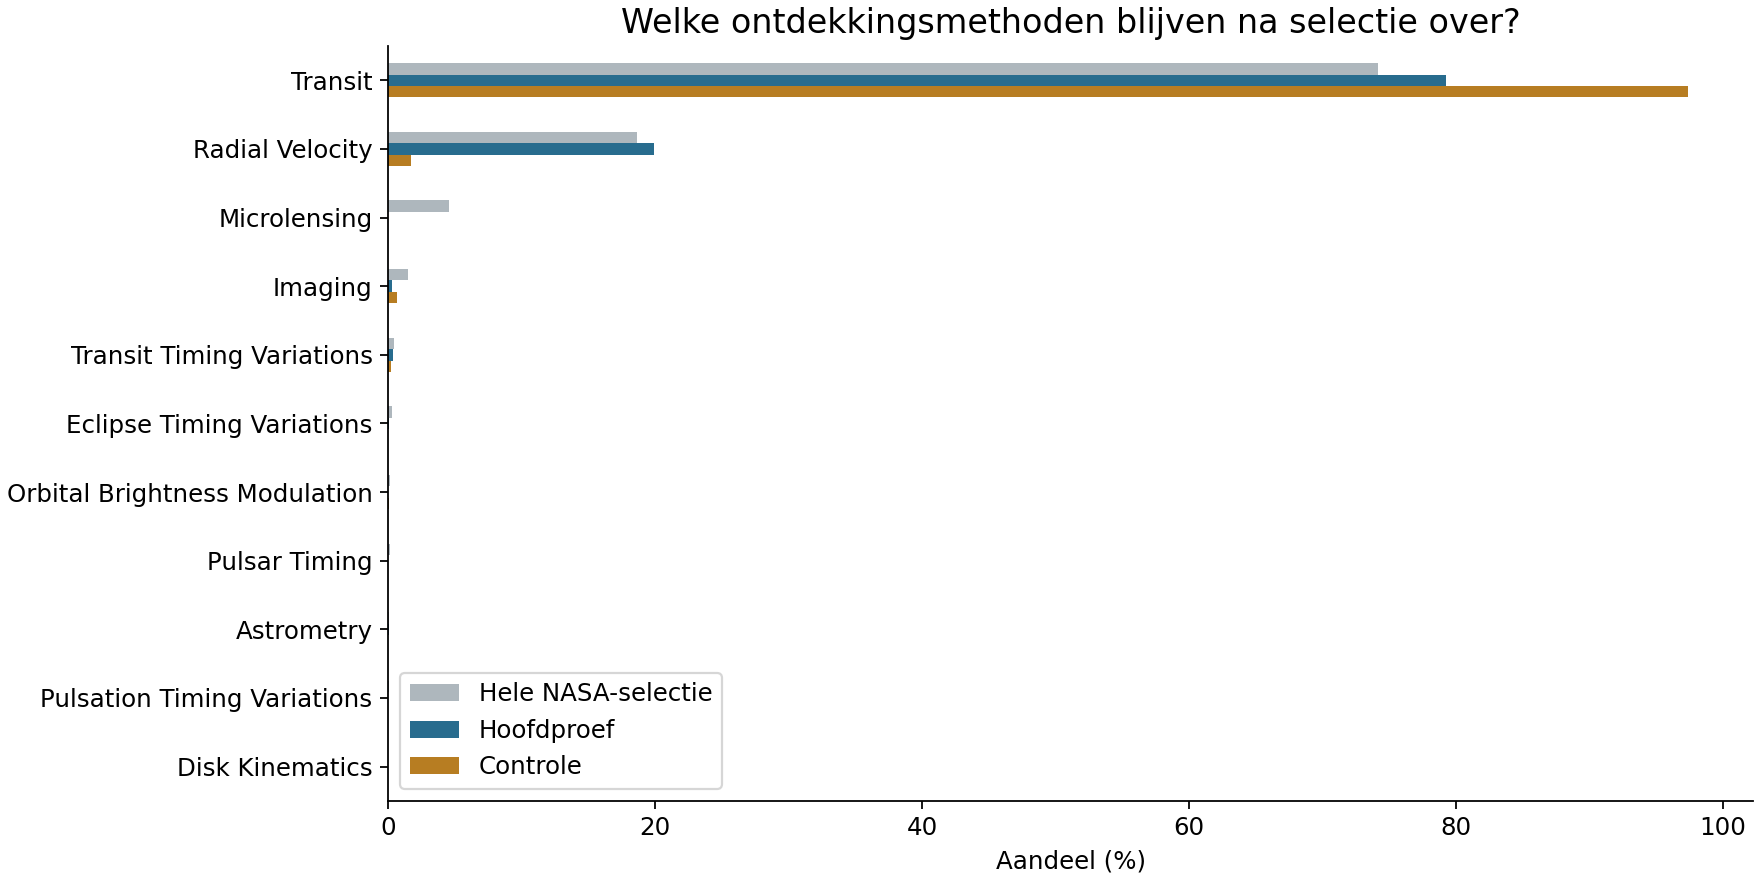

In [9]:
display(Image(filename=str(ROOT/'results/selectiebias.png')))

## Wat nemen we mee?
De SOM werkt op de nieuwe gegevens en levert interpreteerbare verschillen in grootte, temperatuur, banen en gaststerren. De groepsprofielen laten kleine hete planeten, grotere planeten met korte banen, en zware planeten met langere banen zien. Dat zijn voorlopige beschrijvingen van deze kaart, geen bewezen nieuwe planeetsoorten.

Het aantal twaalf is vooraf gekozen. De gegevensselectie, ingevulde waarden, minimum-massa’s, schaling, onderling afhankelijke kenmerken en trainingsvolgorde kunnen de indeling beïnvloeden. Herhaling met andere startgewichten onder dezelfde vaste rijvolgorde is een beperkte stabiliteitscontrole.

Een logisch volgend experiment is dezelfde SOM te gebruiken met aangepaste schaling en minder onderling afhankelijke kenmerken; dat experiment is hier nog niet uitgevoerd.

## Bronnen en reproduceerbaarheid
- [Oorspronkelijk project](https://github.com/Lebo124/Exoplanets)
- [NASA: over PSCompPars](https://exoplanetarchive.ipac.caltech.edu/docs/pscp_about.html)
- [NASA: hoe waarden worden berekend](https://exoplanetarchive.ipac.caltech.edu/docs/pscp_calc.html)
- [NASA: kolommen en eenheden](https://exoplanetarchive.ipac.caltech.edu/docs/API_TD_columns.html)

De exacte query, ophaaltijd en bestandshash staan in `data/provenance.json`. `analysis.py` bevat de volledige code. `results/planeten_met_groepen.csv` bevat elke gebruikte planeet, bronverwijzingen en groepsnummer; `results/groepsprofielen.csv` de groepsmedians. De modelgewichten en schaalgrenzen zijn bewaard in `results/som_model.npz`.
